# 07 — Model Evaluation and Comparison

Final comparison of all models on identical data, followed by a detailed analysis of the selected model.
**Selection rule (fixed before looking at tuned test results):** the model with the lowest mean validation MAE over
the 5 expanding folds. Test-period results (Jun–Oct 2024, rolling one-month-ahead) are reported for every model but
were never used to choose. All errors are in **kWh per household-month**.

Contents: 1 Model comparison · 2 Is the improvement meaningful? · 3 Selected model: predictions and residuals ·
4 Performance over months and household groups · 5 Feature importance · 6 Over-fitting · 7 History vs history + survey ·
8 Unseen households · 9 Robustness · 10 Conclusions

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import plot_style as ps
from src.data_loader import CONSUMPTION_UNIT as U
from src.models import make_pipeline, MODEL_INFO
from src.train import load_modelling_data, run_model, load_summaries, load_test_predictions, load_cv
from src.evaluate import regression_metrics, per_month_metrics
ps.apply(); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
F, train, test = load_modelling_data()
print(f"Training rows: {len(train):,} ({train.month.min():%Y-%m}…{train.month.max():%Y-%m}) | "
      f"test rows: {len(test):,} ({test.month.min():%Y-%m}…{test.month.max():%Y-%m}) | unit: {U}")

Training rows: 68,485 (2023-01…2024-05) | test rows: 20,094 (2024-06…2024-10) | unit: kWh


In [2]:
sel = json.loads((ROOT / "artifacts/model_selection.json").read_text())
FINAL = sel["final_model"]
print(json.dumps(sel, indent=2))
allres = load_summaries()
base = allres[(allres.experiment == "main")]
tuned = allres[(allres.experiment == "tuned")]
untuned = allres[(allres.experiment == "untuned")]

{
  "voting_members": [
    "gradient_boosting",
    "xgboost",
    "random_forest"
  ],
  "stacking_tree_bases": [
    "random_forest",
    "gradient_boosting"
  ],
  "final_model": "voting",
  "final_cv_MAE": 18.779777510215734,
  "rule": "lowest mean validation MAE over the 5 expanding folds (experiment 'tuned')"
}


## 1. Model comparison (history-only features, all households)

In [3]:
comp = pd.concat([base.assign(version="baseline"), untuned.assign(version="untuned"), tuned.assign(version="tuned")])
comp = comp[comp.feature_set == "history_only"]
final_table = pd.concat([base, tuned]).set_index("label")
cols = ["model", "family", "cv_MAE", "cv_MAE_std", "cv_RMSE", "cv_R2", "test_MAE", "test_RMSE", "test_R2", "train_MAE", "fit_seconds_full", "predict_ms_per_1000_rows"]
ranked = final_table[cols].sort_values("cv_MAE")
ranked.insert(0, "rank", range(1, len(ranked) + 1))
ranked.round(3)

,rank,model,family,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,test_MAE,test_RMSE,test_R2,train_MAE,fit_seconds_full,predict_ms_per_1000_rows
label,,,,,,,,,,,,,
voting,1,Voting Regressor,Ensemble combination,18.780,2.309,42.850,0.890,19.675,44.988,0.882,15.842,152.588,34.598
gradient_boosting,2,Gradient Boosting,Boosting,18.907,2.382,43.603,0.886,20.021,45.494,0.880,16.458,145.277,13.523
stacking,3,"Stacking (time-ordered, Ridge meta-learner)",Ensemble combination,18.981,2.458,42.448,0.892,19.626,43.831,0.888,16.821,1052.386,35.369
xgboost,4,XGBoost,Boosting,19.054,2.060,45.720,0.875,20.374,50.093,0.854,17.159,2.072,4.287
random_forest,5,Random Forest,Bagging,19.226,2.537,42.799,0.890,19.601,43.680,0.889,14.600,6.256,14.747
extra_trees,6,Extra Trees,Bagging,19.245,2.387,42.879,0.890,20.059,44.088,0.887,12.775,5.123,14.274
naive_last_month,7,Naive: last month's bill,Baseline,19.695,2.484,47.836,0.861,19.491,48.843,0.861,18.969,0.001,1.325
ridge,8,Ridge Regression,Baseline,20.806,3.546,45.014,0.879,19.889,43.414,0.890,18.409,0.141,2.177
linear,9,Linear Regression,Baseline,20.910,3.800,44.871,0.880,20.618,44.167,0.886,18.322,0.169,2.199


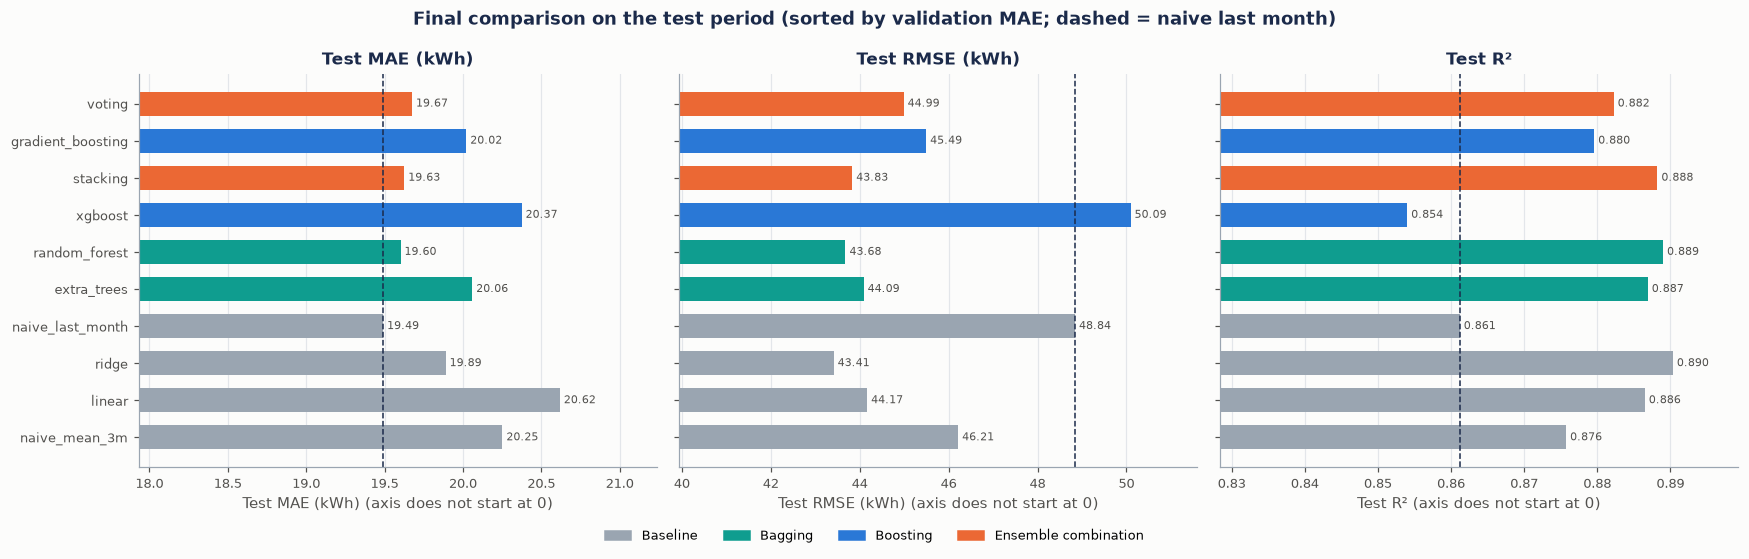

In [4]:
t = ranked.drop(index="dummy_mean")
fam_col = {"Baseline": ps.MUTED, "Bagging": ps.TEAL, "Boosting": ps.BLUE, "Ensemble combination": ps.ORANGE}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for a, m_, ttl in [(axes[0], "test_MAE", f"Test MAE ({U})"), (axes[1], "test_RMSE", f"Test RMSE ({U})"), (axes[2], "test_R2", "Test R²")]:
    a.barh(t.index, t[m_], color=[fam_col[f] for f in t.family], height=0.65)
    lo = t[m_].min() * (0.92 if m_ != "test_R2" else 0.97); hi = t[m_].max() * (1.03 if m_ != "test_R2" else 1.01)
    a.set_xlim(lo, hi); a.grid(axis="y", visible=False)
    a.axvline(t.loc["naive_last_month", m_], color=ps.NAVY, ls="--", lw=1)
    for i, v in enumerate(t[m_]): a.text(v, i, f" {v:.3f}" if m_ == "test_R2" else f" {v:.2f}", va="center", fontsize=7.5, color=ps.INK_2)
    a.set(title=ttl, xlabel=f"{ttl} (axis does not start at 0)")
axes[0].invert_yaxis()
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_col.values()]
fig.legend(handles, fam_col.keys(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.05))
fig.suptitle("Final comparison on the test period (sorted by validation MAE; dashed = naive last month)", color=ps.NAVY, fontweight="bold")
plt.tight_layout(); plt.show()

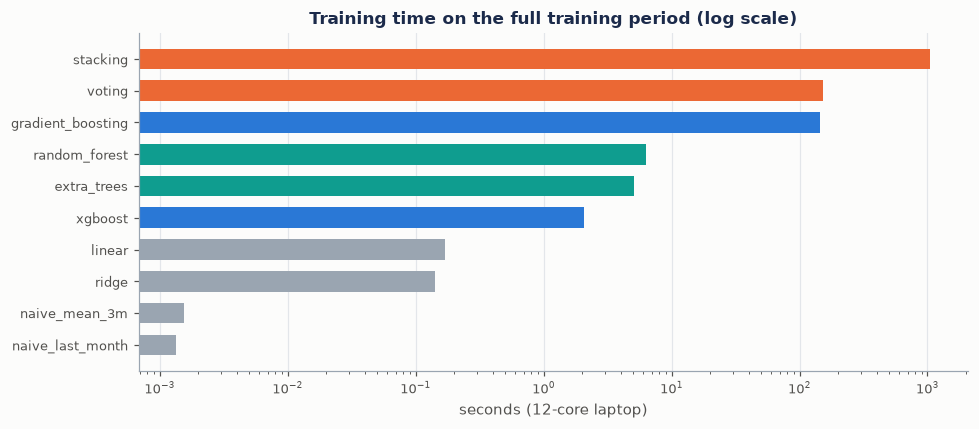

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
tt = t.sort_values("fit_seconds_full")
ax.barh(tt.index, tt.fit_seconds_full.clip(lower=0.001), color=[fam_col[f] for f in tt.family], height=0.65)
ax.set_xscale("log"); ax.grid(axis="y", visible=False)
ax.set(title="Training time on the full training period (log scale)", xlabel="seconds (12-core laptop)")
plt.tight_layout(); plt.show()

**Observation.**

* **Selected model (pre-registered rule): Voting** (Gradient Boosting + XGBoost + Random Forest), validation MAE
  **18.78 kWh**, the lowest of all models, ahead of Gradient Boosting (18.91), Stacking (18.98), XGBoost (19.05), Random
  Forest (19.23), Extra Trees (19.24) and the naive forecast (19.70).
* **Test period:** Voting has MAE **19.67**, RMSE **44.99**, R² **0.882**. The naive forecast has the lowest test MAE
  (19.49) but the worst RMSE of the learned models (48.84); Ridge (43.41), Random Forest (43.68) and Stacking (43.83)
  have the lowest test RMSE.
* **By family:** combination methods were best on validation; bagging (Random Forest) was the most stable from
  validation to test (+0.38 kWh); boosting gained most from tuning on validation but lost most on test (+1.1 to
  +1.3 kWh).
* **Cost:** single tree ensembles train in 2–150 s; Voting ≈ 150 s; time-ordered Stacking ≈ 17 minutes, because its
  base models are refitted for every out-of-fold month.

## 2. Is the improvement meaningful?

The difference in test MAE between two models is estimated with a **household-level bootstrap**: households (not
individual months) are resampled with replacement 1,000 times, because the 5 test months of one household are not
independent. If the 95% interval of "model MAE − naive MAE" lies entirely below 0, the improvement is unlikely to be
chance.

In [6]:
def load_pred(label):
    exp = "main" if label in ("naive_last_month", "ridge", "linear", "naive_mean_3m", "dummy_mean") else "tuned"
    return load_test_predictions(exp, label)
P = load_pred("naive_last_month")[["household_ID", "month", "actual"]].copy()
for l in ["naive_last_month", "ridge", "random_forest", "extra_trees", "gradient_boosting", "xgboost", "voting", "stacking"]:
    P[l] = load_pred(l).predicted.to_numpy()
hh_codes, hh_idx = np.unique(P.household_ID, return_inverse=True)
def boot_diff(a, b, n=1000, seed=0):
    ea, eb = np.abs(P[a] - P.actual).to_numpy(), np.abs(P[b] - P.actual).to_numpy()
    sa, sb = np.bincount(hh_idx, ea), np.bincount(hh_idx, eb); cnt = np.bincount(hh_idx)
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        s = rng.integers(0, len(cnt), len(cnt)); w = np.bincount(s, minlength=len(cnt))
        out.append((w @ sa) / (w @ cnt) - (w @ sb) / (w @ cnt))
    out = np.array(out)
    return (ea.mean() - eb.mean()), *np.percentile(out, [2.5, 97.5])
rows = []
for l in ["ridge", "random_forest", "extra_trees", "gradient_boosting", "xgboost", "voting", "stacking"]:
    d, lo, hi = boot_diff(l, "naive_last_month")
    rows.append({"model": l, "MAE difference vs naive": d, "95% CI low": lo, "95% CI high": hi,
                 "relative change": d / np.abs(P.naive_last_month - P.actual).mean(),
                 "significant improvement": hi < 0, "significantly worse": lo > 0})
boot = pd.DataFrame(rows).set_index("model"); boot.round(3)

,MAE difference vs naive,95% CI low,95% CI high,relative change,significant improvement,significantly worse
model,,,,,,
ridge,0.399,0.110,0.674,0.020,False,True
random_forest,0.111,-0.232,0.406,0.006,False,False
extra_trees,0.568,0.206,0.886,0.029,False,True
gradient_boosting,0.530,0.137,0.912,0.027,False,True
xgboost,0.883,0.277,1.646,0.045,False,True
voting,0.184,-0.196,0.581,0.009,False,False
stacking,0.135,-0.167,0.379,0.007,False,False


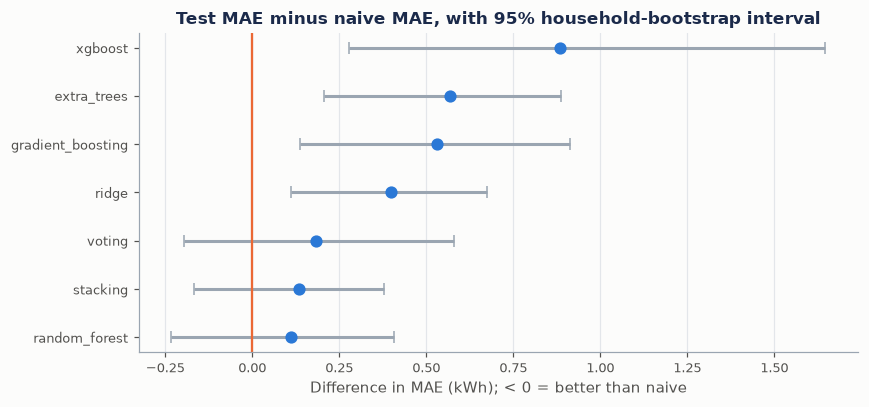

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
b = boot.sort_values("MAE difference vs naive")
ax.errorbar(b["MAE difference vs naive"], b.index, xerr=[b["MAE difference vs naive"] - b["95% CI low"], b["95% CI high"] - b["MAE difference vs naive"]],
            fmt="o", color=ps.BLUE, ecolor=ps.MUTED, capsize=4, ms=7)
ax.axvline(0, color=ps.ORANGE, lw=1.5); ax.grid(axis="y", visible=False)
ax.set(title="Test MAE minus naive MAE, with 95% household-bootstrap interval", xlabel=f"Difference in MAE ({U}); < 0 = better than naive")
plt.tight_layout(); plt.show()

**Observation.** No model is **significantly better** than the naive forecast on test MAE: every 95% interval contains
0 or lies above it. Voting (+0.18, CI −0.20 to +0.58), Stacking (+0.14) and Random Forest (+0.11) are **statistically
indistinguishable** from the naive forecast. Gradient Boosting, XGBoost, Extra Trees and Ridge are **significantly
worse** on test MAE (their intervals lie entirely above 0).

**So is the improvement meaningful?** On validation the selected model improved MAE by 0.9 kWh (≈ 5%); on the test
period that improvement did not hold for MAE, while the ≈ 8% reduction in RMSE (fewer large errors) did. The honest
conclusion is that, for one-month-ahead prediction of known households, ensembles mainly reduce **large** errors; for
the typical household they are no better than "same as last month".

## 3. Selected model: actual vs predicted and residuals

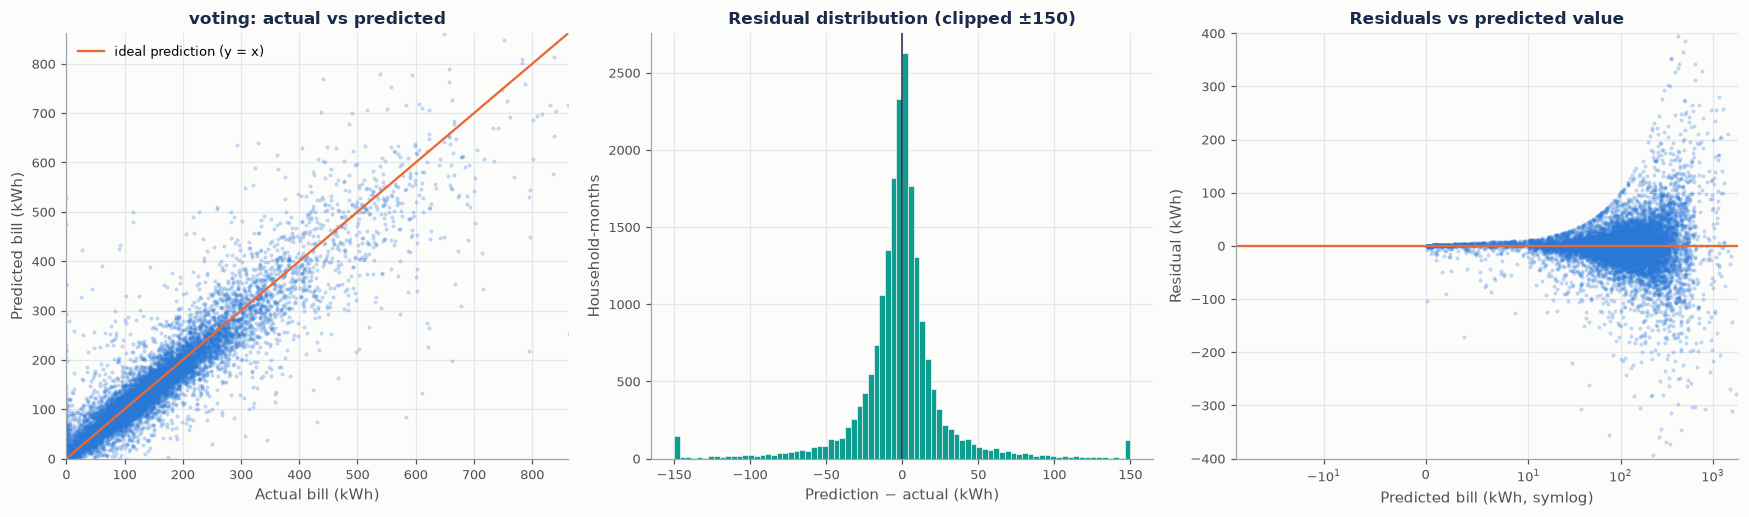

Mean residual (bias): -1.98 kWh | median residual: -0.50 kWh
Median |error|: 9.5 | 90th pct: 43.9 | 99th pct: 167.3 kWh
Worst 5% of rows cause 35.2% of total absolute error


In [8]:
p = load_pred(FINAL); res_ = p.predicted - p.actual
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
lim = p[["actual", "predicted"]].quantile(.995).max()
ax[0].scatter(p.actual, p.predicted, s=3, alpha=0.2, color=ps.BLUE)
ax[0].plot([0, lim], [0, lim], color=ps.ORANGE, lw=1.5, label="ideal prediction (y = x)")
ax[0].set(xlim=(0, lim), ylim=(0, lim), title=f"{FINAL}: actual vs predicted", xlabel=f"Actual bill ({U})", ylabel=f"Predicted bill ({U})"); ax[0].legend(loc="upper left")
ax[1].hist(res_.clip(-150, 150), bins=80, color=ps.TEAL, edgecolor=ps.SURFACE, linewidth=0.4); ax[1].axvline(0, color=ps.NAVY, lw=1)
ax[1].set(title="Residual distribution (clipped ±150)", xlabel=f"Prediction − actual ({U})", ylabel="Household-months")
ax[2].scatter(p.predicted, res_, s=3, alpha=0.2, color=ps.BLUE); ax[2].axhline(0, color=ps.ORANGE, lw=1.5)
ax[2].set_xscale("symlog", linthresh=10); ax[2].set_ylim(-400, 400)
ax[2].set(title="Residuals vs predicted value", xlabel=f"Predicted bill ({U}, symlog)", ylabel=f"Residual ({U})")
plt.tight_layout(); plt.show()
ae = res_.abs()
print(f"Mean residual (bias): {res_.mean():+.2f} {U} | median residual: {res_.median():+.2f} {U}")
print(f"Median |error|: {ae.median():.1f} | 90th pct: {ae.quantile(.9):.1f} | 99th pct: {ae.quantile(.99):.1f} {U}")
print(f"Worst 5% of rows cause {ae.nlargest(int(len(ae)*.05)).sum() / ae.sum():.1%} of total absolute error")

**Observation.** Most predictions are close: median absolute error **9.5 kWh**, 90th percentile 43.9 kWh. The error
distribution is very heavy-tailed: the worst 5% of household-months cause **35%** of the total absolute error (the 99th
percentile error is 167 kWh). These are households whose bill jumped or collapsed compared with their history. The
model slightly under-predicts on average (mean residual −2.0 kWh), mostly because of October 2024 (section 10).
Residuals spread out as predictions grow — larger households have larger absolute errors.

## 4. Performance across test months and household groups

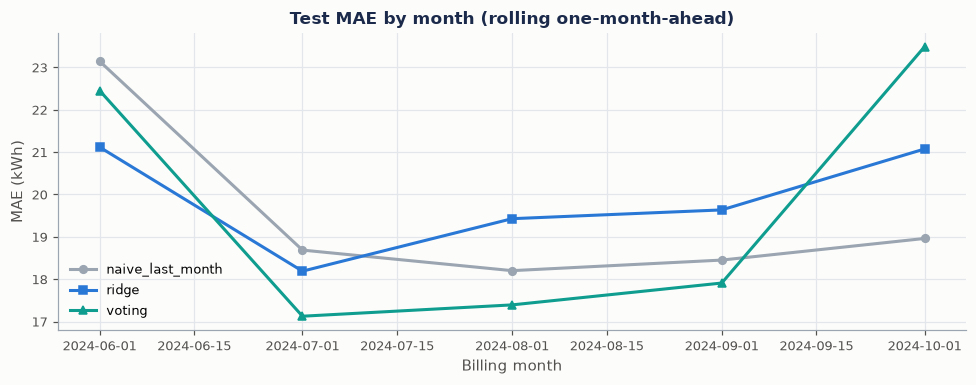

,naive_last_month,ridge,voting
month,,,
2024-06-01,23.15,21.12,22.45
2024-07-01,18.69,18.19,17.13
2024-08-01,18.20,19.43,17.39
2024-09-01,18.45,19.64,17.91
2024-10-01,18.96,21.07,23.49


In [9]:
pm = pd.concat({l: per_month_metrics(load_pred(l)).set_index("month")["MAE"] for l in ["naive_last_month", "ridge", FINAL]}, axis=1)
fig, ax = plt.subplots(figsize=(9, 3.6))
for l, c, mk in zip(pm.columns, [ps.MUTED, ps.BLUE, ps.TEAL], ["o", "s", "^"]):
    ax.plot(pm.index, pm[l], marker=mk, color=c, label=l)
ax.set(title="Test MAE by month (rolling one-month-ahead)", xlabel="Billing month", ylabel=f"MAE ({U})"); ax.legend()
plt.tight_layout(); plt.show(); pm.round(2)

In [10]:
hf = pd.read_parquet(ROOT / "data/processed/household_features_w1.parquet").set_index("household_ID")
pre_mean = train.groupby("household_ID").consumption.mean()       # level from TRAINING months only
level = pd.qcut(pre_mean, 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"])
G = P.join(level.rename("level"), on="household_ID").join(hf[["socio_economic_class", "meter_type"]], on="household_ID")
G["volatility"] = G.household_ID.map(train.groupby("household_ID").consumption.std() / train.groupby("household_ID").consumption.mean().replace(0, np.nan))
G["volatility"] = pd.qcut(G.volatility, 3, labels=["stable", "medium", "volatile"])
def group_table(col):
    g = G.groupby(col, observed=True)
    out = pd.DataFrame({"rows": g.size(), "mean bill": g.actual.mean(),
                        "naive MAE": g.apply(lambda d: (d.naive_last_month - d.actual).abs().mean(), include_groups=False),
                        f"{FINAL} MAE": g.apply(lambda d: (d[FINAL] - d.actual).abs().mean(), include_groups=False)})
    out["MAE % of mean bill"] = 100 * out[f"{FINAL} MAE"] / out["mean bill"]
    out["gain vs naive"] = out["naive MAE"] - out[f"{FINAL} MAE"]
    return out.round(2)
for c in ["level", "volatility", "socio_economic_class", "meter_type"]:
    print(f"\nBy {c}:"); display(group_table(c))


By level:


,rows,mean bill,naive MAE,voting MAE,MAE % of mean bill,gain vs naive
level,,,,,,
Q1 lowest,4007,38.94,9.14,9.22,23.68,-0.08
Q2,4032,75.54,12.17,12.01,15.90,0.16
Q3,4002,101.97,14.76,14.77,14.49,-0.02
Q4,4019,139.35,17.42,17.41,12.49,0.02
Q5 highest,4034,291.72,43.84,44.85,15.37,-1.00



By volatility:


,rows,mean bill,naive MAE,voting MAE,MAE % of mean bill,gain vs naive
volatility,,,,,,
stable,6692,131.37,12.85,13.58,10.34,-0.73
medium,6690,141.17,19.33,19.75,13.99,-0.42
volatile,6687,116.85,26.30,25.70,22.00,0.60



By socio_economic_class:


,rows,mean bill,naive MAE,voting MAE,MAE % of mean bill,gain vs naive
socio_economic_class,,,,,,
SEC A,3898,196.64,29.20,29.59,15.05,-0.40
SEC B,4305,137.09,21.36,21.32,15.55,0.05
SEC C,7348,115.26,17.09,17.22,14.94,-0.13
SEC D,3277,92.32,13.55,13.95,15.11,-0.40
SEC E,1266,78.49,12.55,12.60,16.05,-0.05



By meter_type:


,rows,mean bill,naive MAE,voting MAE,MAE % of mean bill,gain vs naive
meter_type,,,,,,
Non smart meter,9293,108.77,16.45,16.44,15.12,0.00
Smart meter,10801,147.64,22.11,22.46,15.21,-0.35


**Observation.**

* **By month:** Voting beats the naive forecast in **July, August and September 2024** (17.1 vs 18.7; 17.4 vs 18.2;
  17.9 vs 18.5 kWh) and is slightly better in June (22.5 vs 23.2), but is much worse in **October 2024** (23.5 vs 19.0).
  June is hard for every model because bills fell after May (average change −9.4 kWh).
* **By consumption level:** absolute errors grow with bill size (MAE 9 kWh for the lowest fifth vs 45 kWh for the
  highest), but *relative* errors fall from 24% to 12–15% of the bill. Voting is slightly worse than naive for the
  highest-consuming fifth (−1.0 kWh).
* **By volatility (from training months):** Voting helps **volatile** households (+0.6 kWh better than naive) and is
  slightly worse for **stable** ones (−0.7). That is the expected role of a learned model: it adds value where simple
  persistence fails.
* **By socio-economic class and meter type:** relative errors are almost identical (≈ 15% of the mean bill) — no group
  is systematically served worse.

## 5. Feature importance

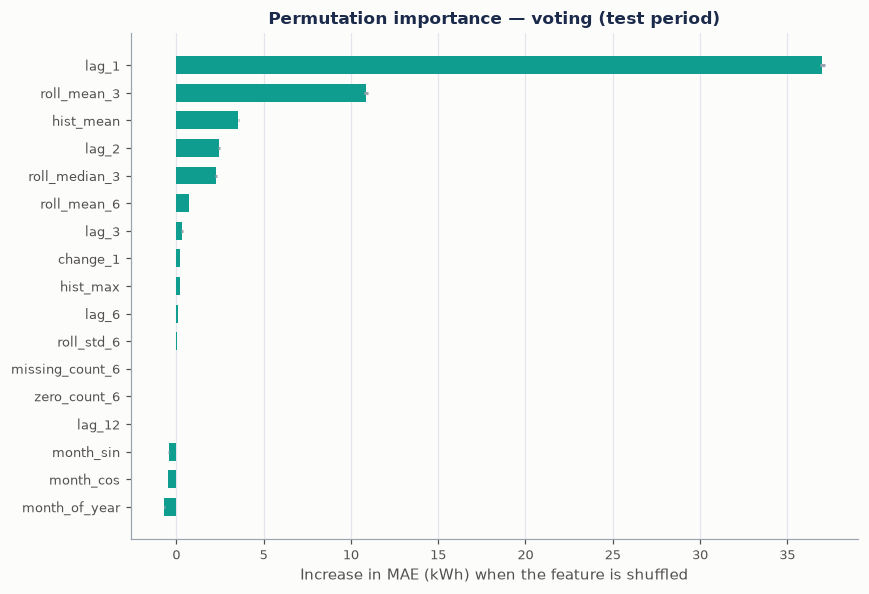

,lag_1,roll_mean_3,hist_mean,lag_2,roll_median_3,roll_mean_6,lag_3,change_1,hist_max,lag_6,roll_std_6,missing_count_6,zero_count_6,lag_12,month_sin,month_cos,month_of_year
MAE increase (kWh),37.003,10.864,3.556,2.426,2.262,0.735,0.337,0.217,0.199,0.092,0.015,0.003,0.003,-0.005,-0.449,-0.471,-0.699


In [11]:
from sklearn.inspection import permutation_importance
from src.preprocessing import model_input_columns
sys.path.insert(0, str(ROOT / "scripts"))
from run_experiments import build
cols = model_input_columns("history_only")
key, final_model, is_stack = build(FINAL)
if is_stack:
    final_model.fit(train[cols], train.consumption.to_numpy(), train.month.to_numpy())
else:
    final_model.fit(train[cols], train.consumption.to_numpy())
pi = permutation_importance(final_model, test[cols], test.consumption.to_numpy(), scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
imp = pd.Series(pi.importances_mean, index=cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(imp.index, imp.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)], color=ps.TEAL, height=0.65, ecolor=ps.MUTED)
ax.grid(axis="y", visible=False)
ax.set(title=f"Permutation importance — {FINAL} (test period)", xlabel=f"Increase in MAE ({U}) when the feature is shuffled")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3).to_frame("MAE increase (kWh)").T

In [12]:
if is_stack:
    print("Stacking meta-learner weights:"); display(final_model.meta_weights_.round(3).to_frame("weight").T)
    members = final_model.bases_
else:
    members = {FINAL: final_model}
for name, pipe in members.items():
    est = getattr(pipe, "named_steps", {}).get("model") if hasattr(pipe, "named_steps") else None
    if est is not None and hasattr(est, "feature_importances_"):
        names = [n.split("__", 1)[1] for n in pipe.named_steps["preprocess"].get_feature_names_out()]
        print(f"\n{name}: built-in importance (top 8)")
        display(pd.Series(est.feature_importances_, index=names).sort_values(ascending=False).head(8).round(3).to_frame().T)

**Observation.** Shuffling **lag_1** (last month's bill) increases the test MAE by **37 kWh** — it is by far the most
important input — followed by roll_mean_3 (10.9), hist_mean (3.6), lag_2 (2.4) and roll_median_3 (2.3). Missing/zero
counts and lag_12 hardly matter.

**The three calendar features have *negative* importance on the test period** (−0.45 to −0.70 kWh): shuffling them
makes test predictions *better*. In other words, the seasonal pattern the models learned from training months did not
hold in Jun–Oct 2024 (see section 10). Built-in tree importances (gain/impurity) of the members also rank lag_1 and the
rolling means first. Importance shows what the model *uses*, not what *causes* consumption.

## 6. Over-fitting: training vs validation vs test

In [13]:
o = pd.concat([base, tuned]).set_index("label").drop(index="dummy_mean")[["train_MAE", "cv_MAE", "test_MAE"]]
o["train→validation gap"] = o.cv_MAE - o.train_MAE
o["validation→test change"] = o.test_MAE - o.cv_MAE
o.sort_values("cv_MAE").round(2)

,train_MAE,cv_MAE,test_MAE,train→validation gap,validation→test change
label,,,,,
voting,15.84,18.78,19.67,2.94,0.90
gradient_boosting,16.46,18.91,20.02,2.45,1.11
stacking,16.82,18.98,19.63,2.16,0.64
xgboost,17.16,19.05,20.37,1.90,1.32
random_forest,14.60,19.23,19.60,4.63,0.38
extra_trees,12.78,19.24,20.06,6.47,0.81
naive_last_month,18.97,19.69,19.49,0.73,-0.20
ridge,18.41,20.81,19.89,2.40,-0.92
linear,18.32,20.91,20.62,2.59,-0.29


**Observation.** Training→validation gaps are largest for Extra Trees (6.5 kWh) and Random Forest (4.6), moderate for
Voting (2.9) and Gradient Boosting (2.5), and smallest for the naive forecast (0.7). Validation→test changes are
**positive for every tree model** (+0.4 to +1.3 kWh) but **negative** for the naive forecast and Ridge — the test
period was not harder for simple persistence, but it was harder for models that learned patterns from the 2023
training months. This points to a change in pattern (non-stationarity), not classic over-fitting to individual rows.

## 7. Does household survey information help? (history-only vs history + Wave 1)

Same tuned hyper-parameters; the only difference is the feature set. Wave 1 features are used only after each
household's interview date (16% of training rows, 78% of test rows).

In [14]:
abl = allres[allres.experiment == "ablation"].set_index("label")
ho = final_table.loc[abl.index]
ab = pd.DataFrame({"history-only val MAE": ho.cv_MAE, "+ survey val MAE": abl.cv_MAE,
                   "history-only test MAE": ho.test_MAE, "+ survey test MAE": abl.test_MAE,
                   "history-only test RMSE": ho.test_RMSE, "+ survey test RMSE": abl.test_RMSE})
ab["Δ val MAE"] = ab["+ survey val MAE"] - ab["history-only val MAE"]
ab["Δ test MAE"] = ab["+ survey test MAE"] - ab["history-only test MAE"]
ab.round(3)

,history-only val MAE,+ survey val MAE,history-only test MAE,+ survey test MAE,history-only test RMSE,+ survey test RMSE,Δ val MAE,Δ test MAE
label,,,,,,,,
extra_trees,19.245,19.268,20.059,19.670,44.088,43.665,0.023,-0.388
gradient_boosting,18.907,18.859,20.021,19.979,45.494,45.519,-0.047,-0.042
random_forest,19.226,19.228,19.601,19.572,43.680,43.769,0.002,-0.029
ridge,20.806,21.599,19.889,20.502,43.414,44.144,0.793,0.612
voting,18.780,18.788,19.675,19.573,44.988,44.945,0.008,-0.102
xgboost,19.054,19.188,20.374,20.239,50.093,49.876,0.134,-0.135


In [15]:
# Where survey data were available at prediction time vs not (test rows), for the final model
ps_ = load_test_predictions("ablation", FINAL, "history_plus_survey")
ph = load_pred(FINAL)
avail = test.survey_available.to_numpy() == 1
print(f"Test rows with survey available: {avail.mean():.1%}")
for name, mask in [("survey available", avail), ("survey not yet available", ~avail)]:
    print(f"{name:26s} history-only MAE {(ph.predicted - ph.actual).abs()[mask].mean():6.2f} | + survey MAE {(ps_.predicted - ps_.actual).abs()[mask].mean():6.2f} {U}")

Test rows with survey available: 78.1%
survey available           history-only MAE  19.11 | + survey MAE  19.19 kWh
survey not yet available   history-only MAE  21.70 | + survey MAE  20.95 kWh


**Observation.** Adding date-masked Wave 1 survey features changes validation MAE by at most ±0.05 kWh for the tree
models (Voting 18.78 → 18.79, Gradient Boosting 18.91 → 18.86) and makes Ridge worse (20.81 → 21.60). Test differences
are also small (Voting 19.67 → 19.57; Extra Trees −0.39; Ridge +0.61). **Household survey information does not
meaningfully improve one-month-ahead prediction when the household's own bill history is available.**

Why? (1) Bill history already summarises the effect of appliances and household size on consumption; (2) under the
leakage-free rule, survey answers exist for only 16% of training rows, so models have little opportunity to learn from
them. The split by availability is not a clean survey effect (both models differ in all trees), so it is not
interpreted further.

## 8. Scenario B — households never seen during training

Households are split into 5 groups; each model is trained on the other groups' training-period rows and evaluated on
the held-out households' test months. These households still have their own billing history (they are existing
customers the model has not seen), so lag features are available.

In [16]:
un = allres[allres.experiment == "unseen_households"].set_index(["label", "feature_set"])[["test_MAE", "test_RMSE", "test_R2", "test_n"]]
scenA = final_table[["test_MAE", "test_RMSE", "test_R2"]].rename(columns=lambda c: "scenario A " + c)
un.join(scenA, on="label").round(3)

test_MAE  test_RMSE  test_R2  test_n  scenario A test_MAE  scenario A test_RMSE  scenario A test_R2
label             feature_set                                                                                                             
gradient_boosting history_only           20.161     46.957    0.872   20094               20.021                45.494               0.880
                  history_plus_survey    20.079     46.942    0.872   20094               20.021                45.494               0.880
naive_last_month  history_only           19.491     48.843    0.861   20094               19.491                48.843               0.861
ridge             history_only           19.859     43.429    0.890   20094               19.889                43.414               0.890
                  history_plus_survey    20.583     44.329    0.886   20094               19.889                43.414               0.890
voting            history_only           19.788     46.173    0.876   20094               19.675                44.988               0.882

**Observation.** For households **never seen during training** (5 group folds; each household held out once), errors
are almost the same as for known households: Voting 19.79 vs 19.67, Gradient Boosting 20.16 vs 20.02, Ridge 19.86 vs
19.89 kWh. The models learn general rules about how a bill history evolves, not facts about individual households —
so they generalise to new customers **as long as those customers have a billing history**. Survey features again add
nothing (Gradient Boosting 20.16 → 20.08; Ridge worse). A truly new household without any bills cannot be predicted
by these models.

## 9. Robustness checks

In [17]:
rb = allres[allres.experiment.str.startswith("robust")].set_index(["experiment", "label"])[["cv_MAE", "test_MAE", "test_RMSE", "test_R2", "test_n"]]
print("Main experiment for reference:"); display(final_table.loc[["naive_last_month", FINAL], ["cv_MAE", "test_MAE", "test_RMSE", "test_R2", "test_n"]].round(3))
print("Robustness experiments:"); rb.round(3)

Main experiment for reference:


,cv_MAE,test_MAE,test_RMSE,test_R2,test_n
label,,,,,
naive_last_month,19.695,19.491,48.843,0.861,20094
voting,18.780,19.675,44.988,0.882,20094


Robustness experiments:


cv_MAE  test_MAE  test_RMSE  test_R2  test_n
experiment         label                                                         
robust_R1_excl34   naive_last_month  19.786    19.581     48.959    0.861   19999
                   voting            18.905    19.764     45.026    0.882   19999
robust_R2_nospikes voting            18.786    19.655     44.948    0.882   20094

**Observation.** Conclusions are robust:

* **R1 — excluding all 34 always-zero / low-activity households:** Voting test MAE 19.76 vs naive 19.58 — the same
  picture as the main experiment.
* **R2 — removing the 10 isolated spikes found in the training months from the training targets:** Voting test MAE
  19.66 vs 19.67 — no meaningful change. Keeping the spikes was harmless.

## 10. POST-HOC diagnostic: why are the test errors larger than validation errors?

> ⚠️ **This section was designed after the test results were seen.** It explains a weakness; it is **not** used to
> select or replace the final model (doing so would turn the test set into a validation set and make the reported test
> results over-optimistic).

In [18]:
months = sorted(P.month.unique())
bias = pd.DataFrame({l: (P[l] - P.actual).groupby(P.month).mean() for l in ["naive_last_month", "random_forest", "gradient_boosting", "xgboost", FINAL]})
mae_m = pd.DataFrame({l: (P[l] - P.actual).abs().groupby(P.month).mean() for l in ["naive_last_month", "random_forest", "gradient_boosting", "xgboost", FINAL]})
print("Mean residual (prediction − actual) per test month, kWh:"); display(bias.round(2))
print("MAE per test month, kWh:"); display(mae_m.round(2))
oct_share = {l: ((P[l] - P.actual).abs()[P.month == months[-1]].sum() - (P.naive_last_month - P.actual).abs()[P.month == months[-1]].sum()) for l in ["gradient_boosting", "xgboost", FINAL]}
print("Extra absolute error vs naive in October 2024 (kWh, summed):", {k: round(v) for k, v in oct_share.items()})

Mean residual (prediction − actual) per test month, kWh:


,naive_last_month,random_forest,gradient_boosting,xgboost,voting
month,,,,,
2024-06-01,9.20,11.89,10.58,11.82,11.43
2024-07-01,2.75,5.72,-0.88,-0.80,1.35
2024-08-01,-5.30,-1.40,-3.15,-3.07,-2.54
2024-09-01,-0.23,-2.87,-5.08,-4.71,-4.22
2024-10-01,-1.64,-10.75,-19.19,-17.87,-15.93


MAE per test month, kWh:


,naive_last_month,random_forest,gradient_boosting,xgboost,voting
month,,,,,
2024-06-01,23.15,22.49,22.15,23.33,22.45
2024-07-01,18.69,18.19,17.11,17.67,17.13
2024-08-01,18.20,17.56,17.43,17.96,17.39
2024-09-01,18.45,18.22,17.89,18.42,17.91
2024-10-01,18.96,21.56,25.52,24.48,23.49


Extra absolute error vs naive in October 2024 (kWh, summed): {'gradient_boosting': 26324, 'xgboost': 22163, 'voting': 18183}


In [19]:
mo = F.assign(m=F.month.dt.month, y=F.month.dt.year).dropna(subset=["consumption"])
seasonal = mo[mo.m.isin([6, 7, 8, 9, 10])].groupby(["y", "m"]).consumption.median().unstack(0)
print("Median bill by calendar month (the training data contain only ONE June–October, all in 2023):"); display(seasonal)
diag = allres[allres.experiment == "posthoc_diagnostic"].set_index(["label", "feature_set"])[["cv_MAE", "test_MAE", "test_RMSE"]]
ref = final_table.loc[["random_forest", "gradient_boosting"], ["cv_MAE", "test_MAE", "test_RMSE"]].assign(feature_set="history_only (main)").set_index("feature_set", append=True)
print("Same tuned models, with and without calendar-month features / lag_12:"); pd.concat([ref, diag]).sort_index().round(3)

Median bill by calendar month (the training data contain only ONE June–October, all in 2023):


y,2022,2023,2024
m,,,
6,NaN,101.0,98.0
7,NaN,96.0,98.0
8,NaN,100.0,101.5
9,NaN,97.0,101.0
10,100.0,90.0,104.0


Same tuned models, with and without calendar-month features / lag_12:


cv_MAE  test_MAE  test_RMSE
label             feature_set                                           
gradient_boosting diag_no_calendar           20.681    18.204     42.850
                  diag_no_calendar_no_lag12  19.495    18.159     42.649
                  history_only (main)        18.907    20.021     45.494
random_forest     diag_no_calendar           20.164    18.773     42.602
                  diag_no_calendar_no_lag12  19.608    18.815     42.783
                  history_only (main)        19.226    19.601     43.680

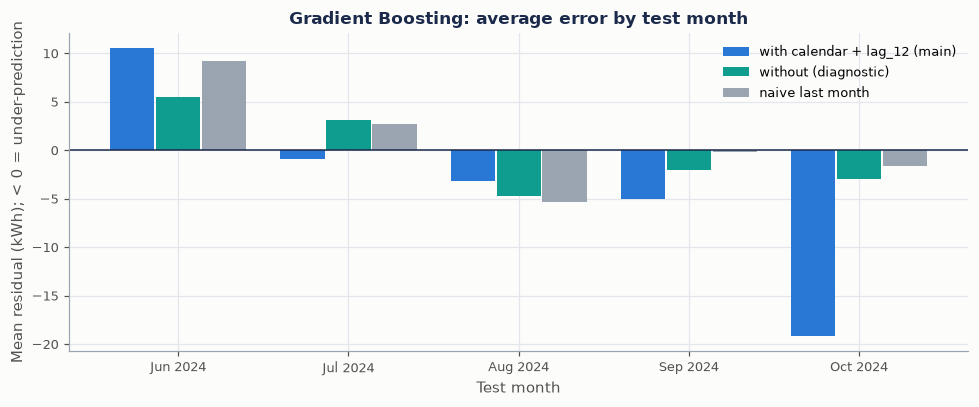

In [20]:
gb_no = load_test_predictions("posthoc_diagnostic", "gradient_boosting", "diag_no_calendar_no_lag12")
d = pd.DataFrame({"with calendar + lag_12 (main)": (P.gradient_boosting - P.actual).groupby(P.month).mean(),
                  "without (diagnostic)": (gb_no.predicted - gb_no.actual).groupby(gb_no.month).mean().values,
                  "naive last month": bias.naive_last_month})
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(d))
for i, (c, col) in enumerate(zip(d.columns, [ps.BLUE, ps.TEAL, ps.MUTED])):
    ax.bar(x + (i - 1) * 0.27, d[c], width=0.26, color=col, label=c)
ax.axhline(0, color=ps.NAVY, lw=1); ax.set_xticks(x); ax.set_xticklabels([pd.Timestamp(m).strftime("%b %Y") for m in d.index])
ax.set(title="Gradient Boosting: average error by test month", ylabel=f"Mean residual ({U}); < 0 = under-prediction", xlabel="Test month")
ax.legend(); plt.tight_layout(); plt.show()

**Finding (post-hoc).** The validation-to-test gap of the tree models is concentrated in **October 2024**: Voting's
mean residual is −15.9 kWh that month (Gradient Boosting −19.2, XGBoost −17.9) versus −1.6 kWh for the naive forecast.

**Cause.** The training targets contain only **one** October (2023), and October 2023 was unusually low (median 90 kWh,
vs 100 in Oct 2022 and 104 in Oct 2024). From that single example the models learned "October bills are lower than
September" through the calendar-month features and lag_12. The pattern did not repeat in 2024. Validation months
(Jan–May 2024) could not reveal this, because each of them had a previous-year counterpart that *did* behave
similarly.

**Evidence.** Re-running the same tuned models **without calendar features and lag_12** removes most of the October
bias (Gradient Boosting −19.2 → −2.9 kWh) and gives the **best test results of the whole project**: Gradient Boosting
test MAE **18.16 kWh** (vs 20.02), RMSE 42.65; Random Forest 18.82 kWh. **But** their validation MAE is *worse*
(19.50 vs 18.91) — so a selection rule that does not look at the test set would not have chosen them.

**Interpretation for the report.** With only ~2 years of monthly data, seasonal features are unreliable: one unusual
month is enough to teach a wrong seasonal pattern. The final model is **not** replaced, because choosing it now would
use the test set for model selection. The correct next step is to collect more years (or add weather data) and
pre-register a model without calendar features for evaluation on *new* months.

## 11. Conclusions

**Answers to the research questions**

1. **Which ensemble technique has the lowest error?** On the pre-registered validation criterion, **Voting** (18.78 kWh
   MAE). On the test period, Voting, Stacking and Random Forest are statistically tied with the naive forecast on MAE
   (≈ 19.5–19.7 kWh); the ensembles reduce RMSE by ≈ 8–11% (43.7–45.0 vs 48.8 kWh).
2. **Does survey information help?** No meaningful improvement once bill history is available (± 0.1 kWh for the
   ensembles; Ridge worse), partly because leakage-free survey data cover only 16% of training rows.
3. **Most important features:** last month's bill (lag_1), followed by the 3-month mean and the long-run mean.
   Calendar features harmed test performance.
4. **Ensembles vs baselines:** ensembles beat Linear/Ridge on MAE on validation and match or beat them on test RMSE;
   none is significantly better than persistence on test MAE.
5. **Future months vs unseen households:** generalisation to unseen households with a billing history is almost as
   good as to known households; performance on future months depends strongly on whether seasonal patterns repeat.

**Overall.** Bagging, Boosting and Stacking were implemented and compared correctly under a leakage-free,
time-ordered design. Their benefit for this task is modest and comes mainly from fewer large errors. The project's
most important lesson is methodological: honest time-ordered evaluation revealed that seasonal effects learned from a
single year do not transfer — a result a random train/test split would have hidden.